In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import scipy
import scipy.integrate
import scipy.stats
import pandas as pd
from multiprocessing import Pool
from functools import partial
import os
import ast

Loading in the grid data, and determining the chisquares between observed + synthetic fits, alongside empty + synthetic fits

/tmp/ipykernel_291751/339215868.py:73: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10, 6))


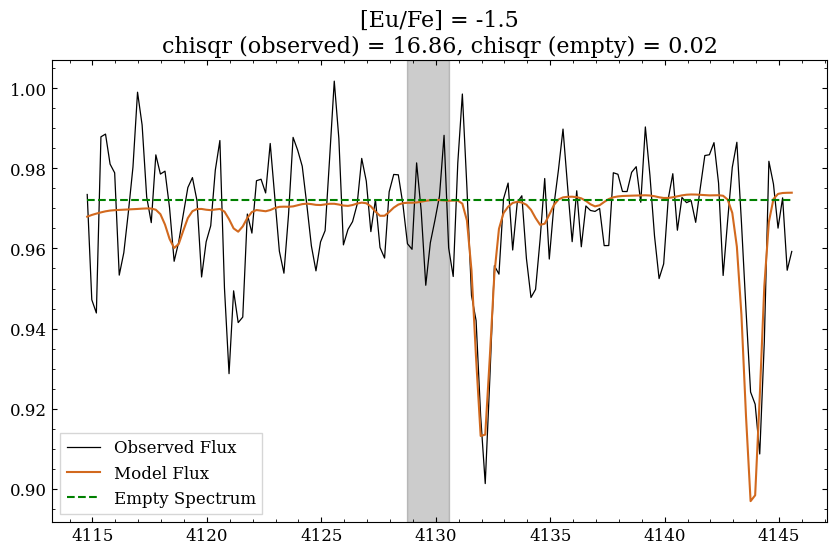

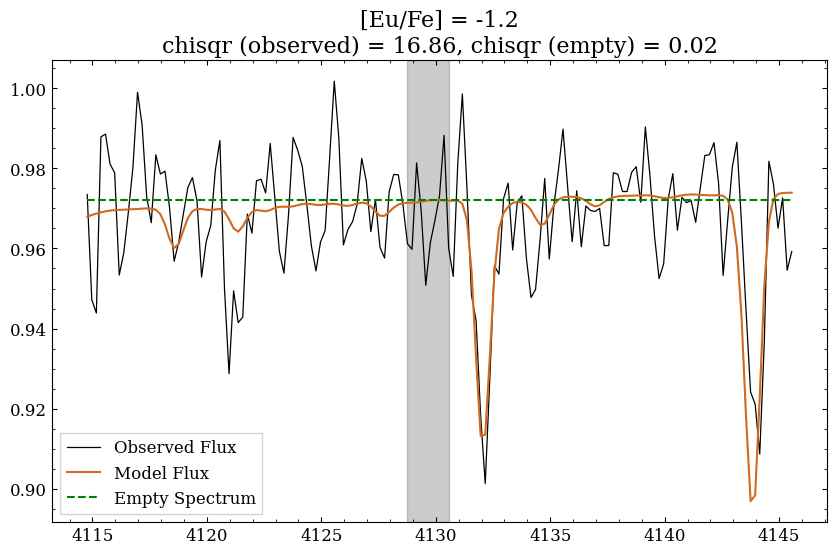

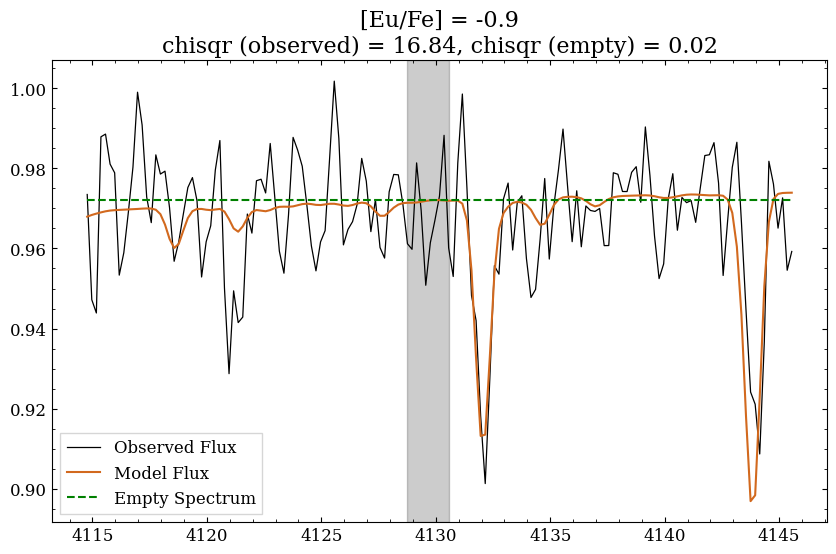

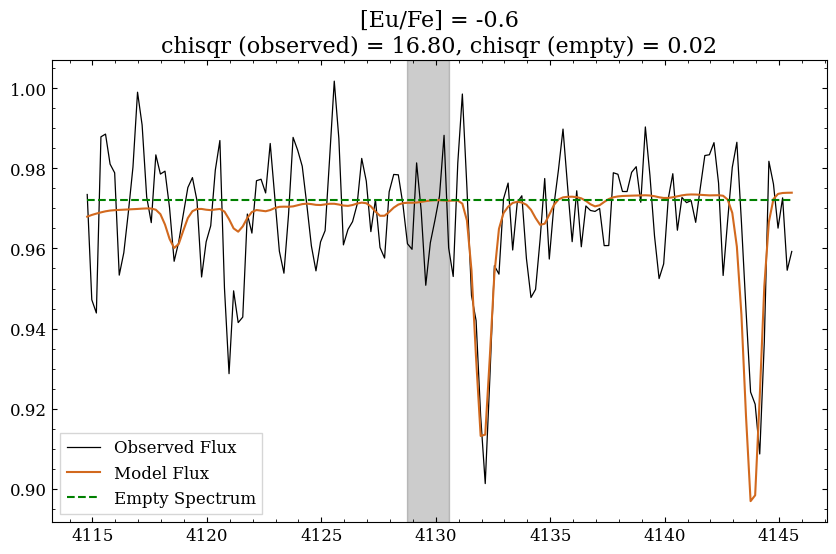

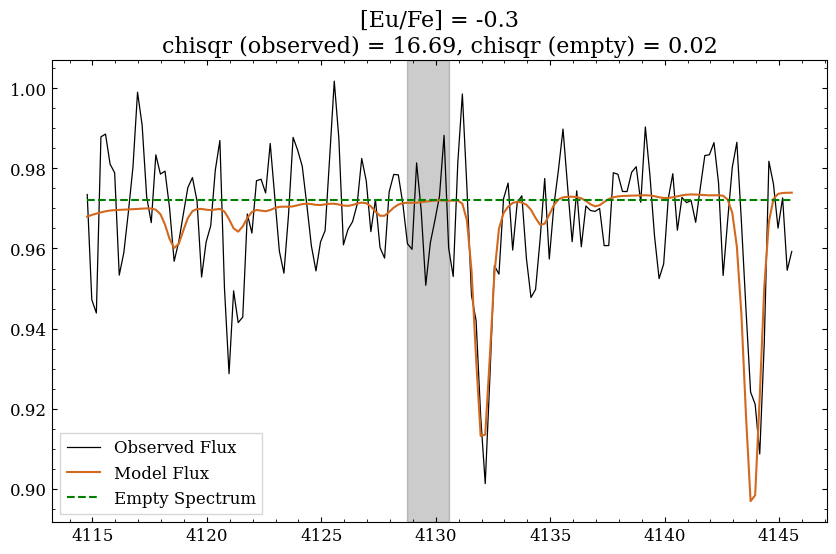

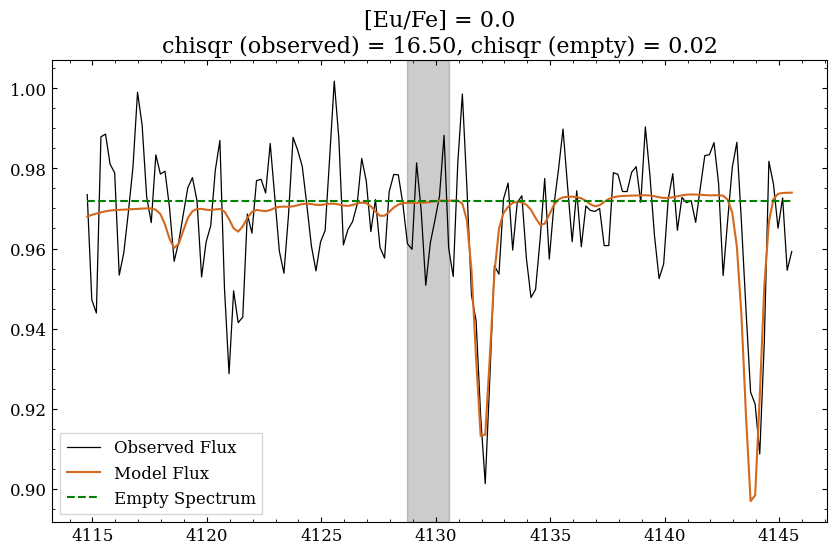

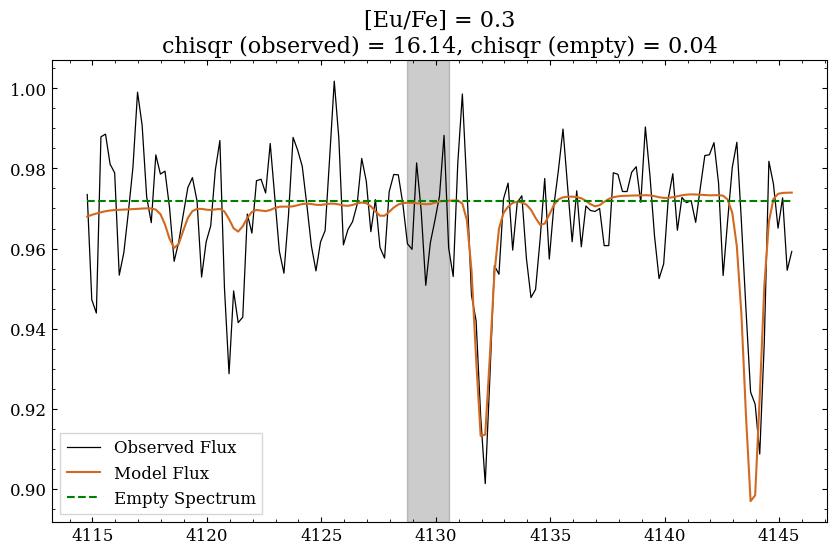

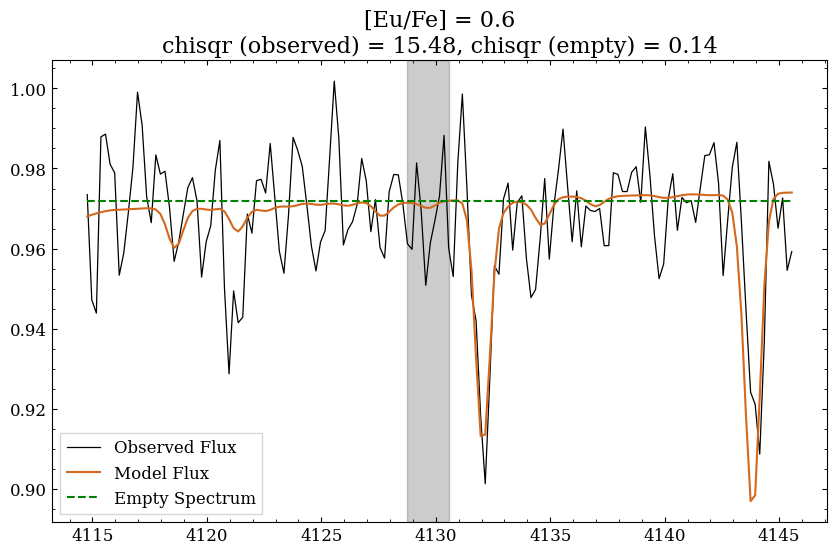

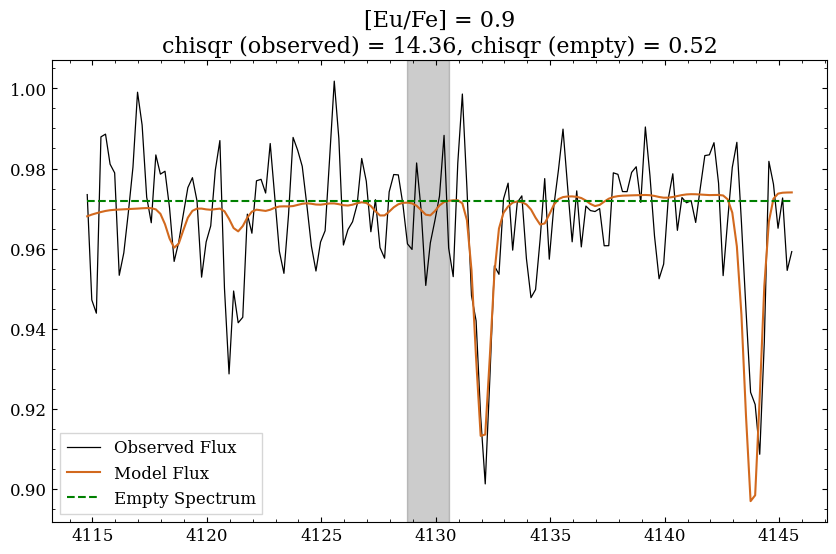

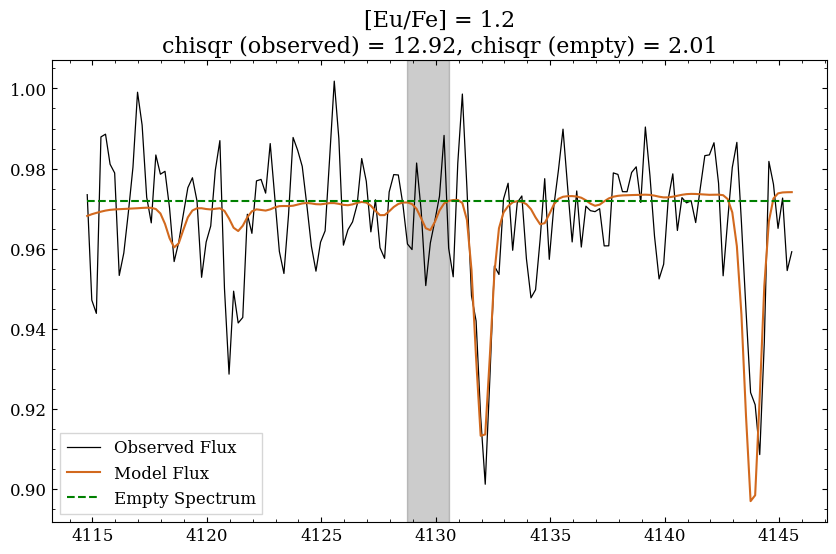

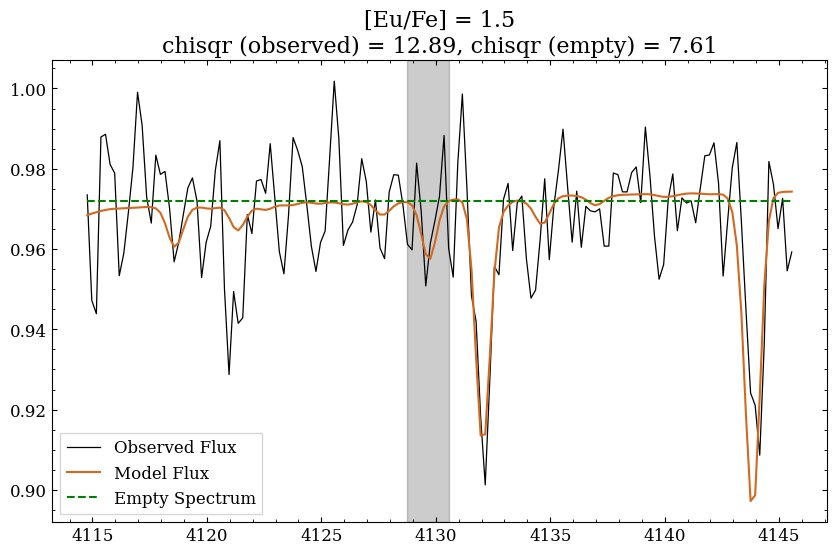

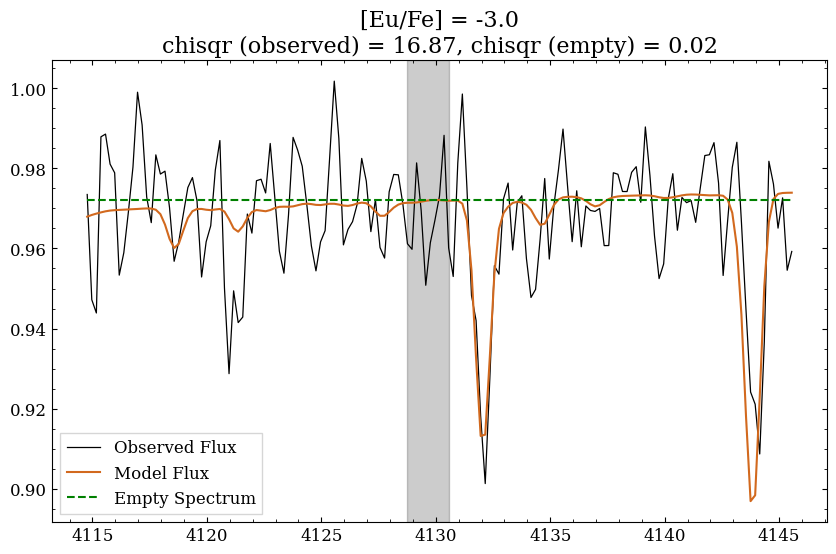

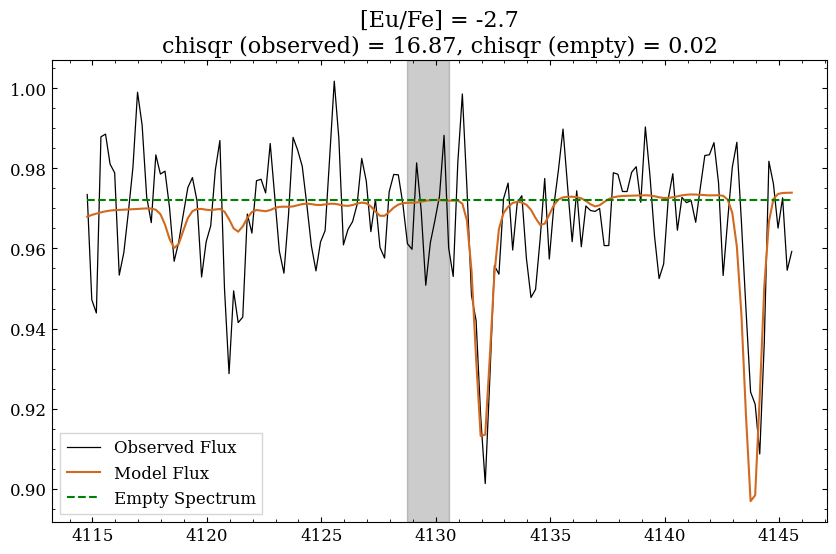

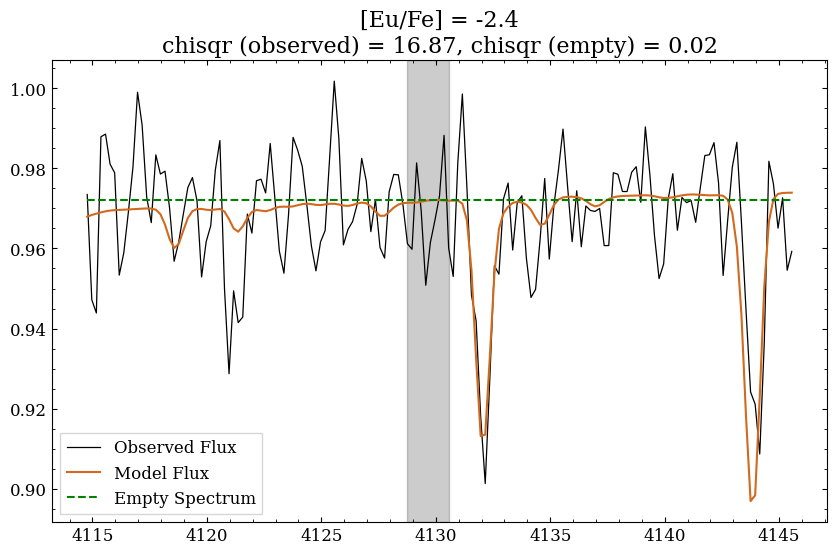

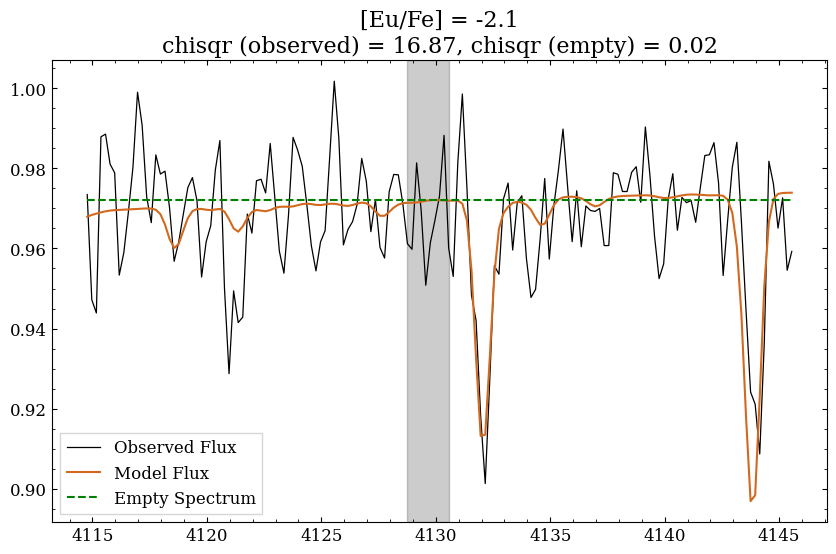

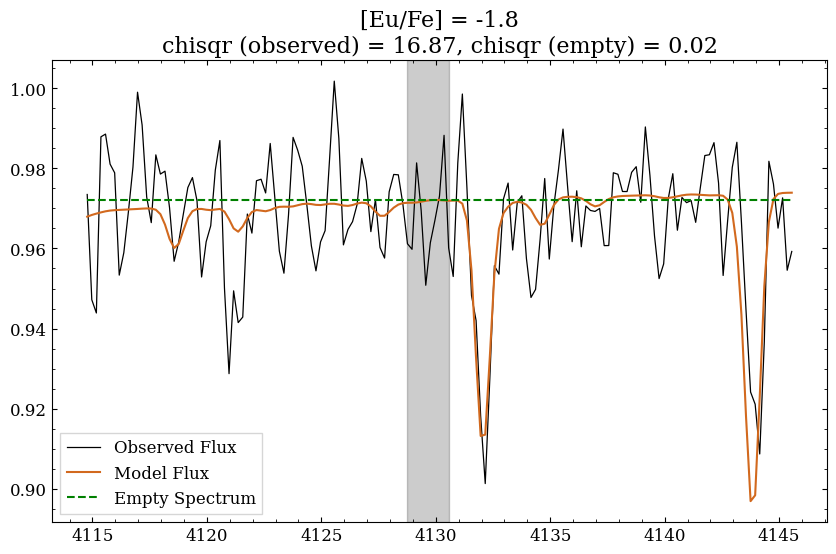

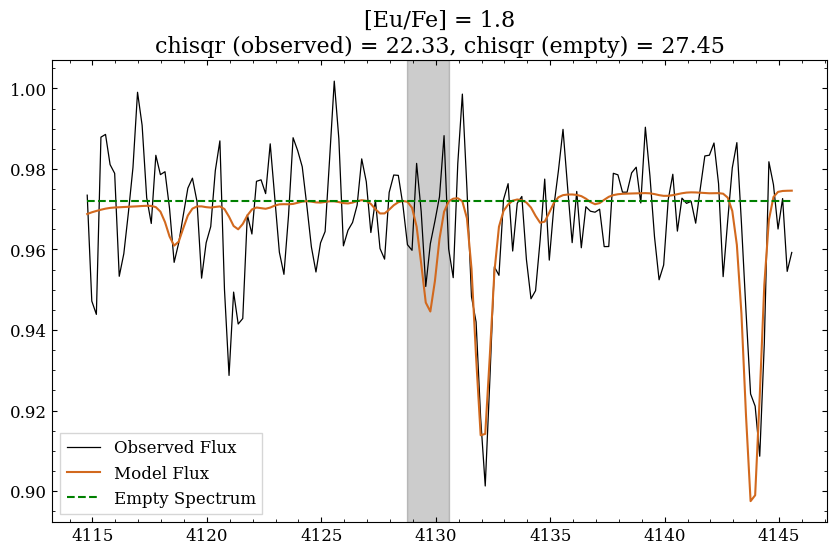

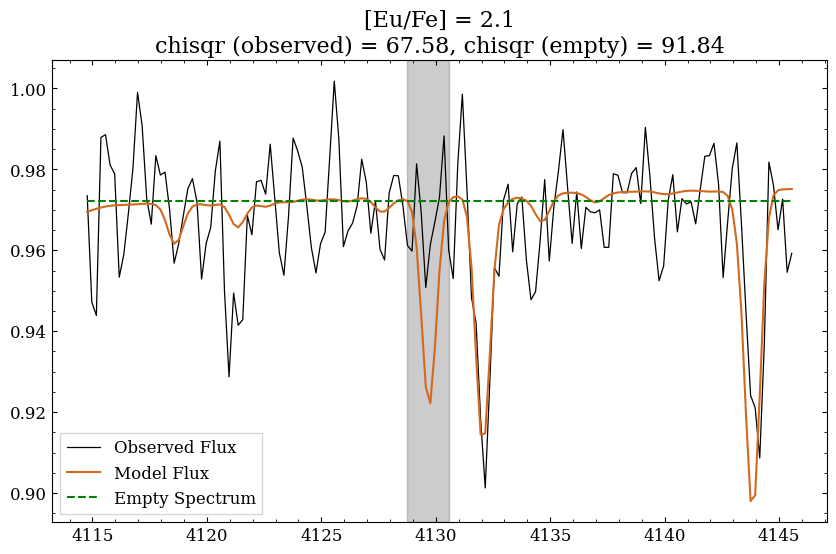

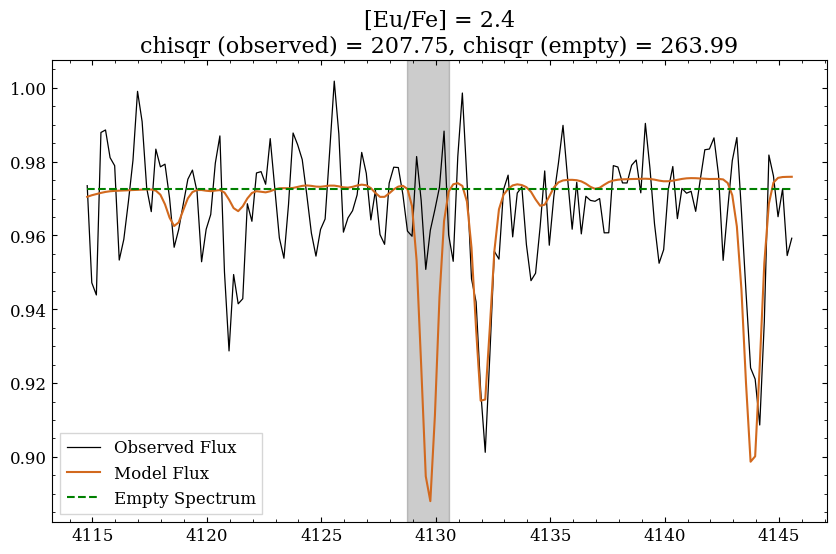

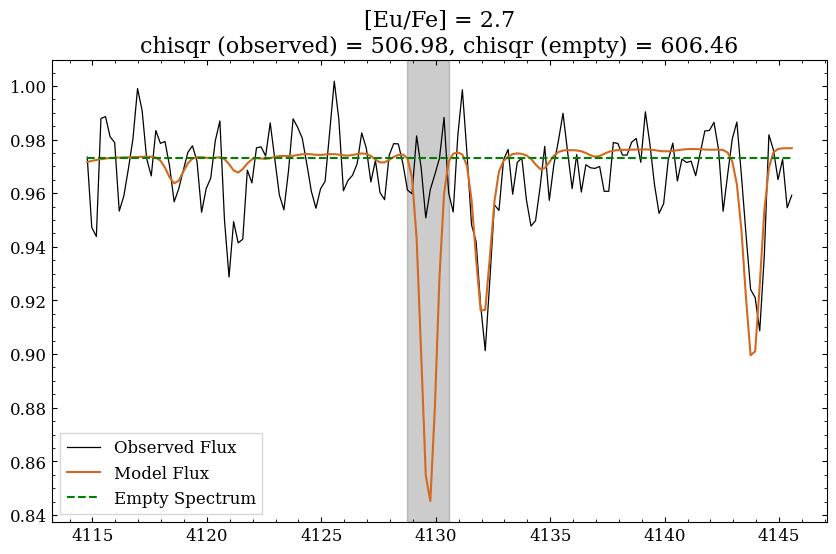

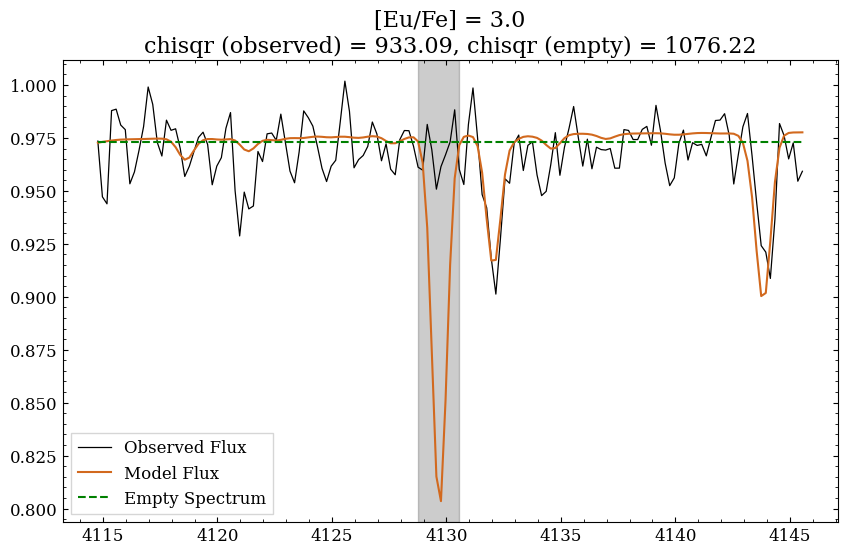

In [18]:
# Loading in the spectra
# spec_path = '/data/misfit/benlowe/xshooter/korg_data/synths/test/test3_emptysynth/ra_1633-2814_s284/Mn_I/obs/line_4033.06/spectra/'
spec_path = '/data/misfit/benlowe/xshooter/korg_data/synths/test/test3_emptysynth/ra_1633-2814_s284/Eu_II/obs/line_4129.725/spectra/'

spec_files = [spec_path + f for f in os.listdir(spec_path) if f.endswith('.csv')]

# Open up each one, then determine the chisquared
def chisqr(obs_flux, obs_err, model_flux):
    """
    Calculate the chi-squared value between observed and model fluxes.
    """
    diff = obs_flux - model_flux
    chi2 = np.sum((diff / obs_err) ** 2)
    return chi2


# Looping through each spectrum file, and calculating the chi-squared values 
# between the observed flux and the model flux, as well as the 'empty' spectrum
chisq_list = []
for f in spec_files:
    
    # Read the spectrum
    all_spec = pd.read_csv(f)
    
    for spec in all_spec.iterrows():
        
        # Getting the grid abundance from the filename
        abund = f.split('/')[-1].split('_')[0]
        el = spec_path.split('/')[-5].split('_')[0]  # Element from the path
        
        # Extracting the spectrum data
        obs_flux = np.array(ast.literal_eval(spec[1]['obs_flux']))
        obs_wave = np.array(ast.literal_eval(spec[1]['obs_wave']))
        obs_flux_err = np.array(ast.literal_eval(spec[1]['obs_flux_err']))
        
        fit_flux = np.array(ast.literal_eval(spec[1]['fit_flux']))
        fit_wave = np.array(ast.literal_eval(spec[1]['fit_wave']))
        
        # Computing the chi-squared value
        # Doing this around the line of interest
        line = float(f.split('/')[-3].split('_')[1])
        
        reg = 1 # +/- 2A around the line
        line_reg = np.where((fit_wave >= line - reg) & (fit_wave <= line + reg))[0]
        
        # Getting the 'empty' spectrum by first taking the top 5% of the fit_flux
        # and then averaging those values to create a flat line for the empty spectrum
        flux_reg = fit_flux[line_reg]
        threshold = np.percentile(flux_reg, 95)
        top_flux = flux_reg[flux_reg >= threshold]
        empty_flux = np.array([np.average(top_flux)] * len(fit_wave))
        
        
        obs_chi2_value = chisqr(obs_flux[line_reg], obs_flux_err[line_reg], fit_flux[line_reg])
        empty_chisq_value = chisqr(empty_flux[line_reg], obs_flux_err[line_reg], fit_flux[line_reg])
        
        chi2_dict = {
            'abund': float(abund),
            'obs_chi2': obs_chi2_value,
            'empty_chi2': empty_chisq_value,
            'line': line,
            'line_reg': line_reg,
            'obs_wave': obs_wave[line_reg],
            'obs_flux': obs_flux[line_reg],
            'obs_flux_err': obs_flux_err[line_reg],
            'fit_wave': fit_wave[line_reg],
            'fit_flux': fit_flux[line_reg],
            'empty_flux': empty_flux[line_reg]
        }
        chisq_list.append(chi2_dict)
        
        # Plotting the results
        plt.figure(figsize=(10, 6))
        plt.title(f"[{el}/Fe] = {abund}\nchisqr (observed) = {obs_chi2_value:.2f}, chisqr (empty) = {empty_chisq_value:.2f}")
        plt.plot(obs_wave, obs_flux, label='Observed Flux', color='black', linewidth=0.9)
        plt.plot(fit_wave, fit_flux, label='Model Flux', color='chocolate')
        plt.plot(fit_wave, empty_flux, label='Empty Spectrum', color='green', linestyle='--')
        plt.axvspan(min(fit_wave[line_reg]), max(fit_wave[line_reg]), color='black', alpha=0.2)
        plt.legend(fancybox=False)
        
        
chisqr_df = pd.DataFrame(chisq_list)

In [14]:
chisqr_df.sort_values(by='abund', ascending=True, inplace=True)
chisqr_df

,abund,obs_chi2,empty_chi2,line,line_reg,obs_wave,obs_flux,obs_flux_err,fit_wave,fit_flux,empty_flux
11,-3.0,7.601919,0.003192,4129.725,"[73, 74, 75, 76, 77]","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9694342460413804, 0.9508126888420154, 0.961...","[0.00879210626065989, 0.008803917973729604, 0....","[4129.362926586663, 4129.562798945162, 4129.76...","[0.971684597373174, 0.9719110715658025, 0.9720...","[0.9721272133417102, 0.9721272133417102, 0.972..."
12,-2.7,7.601919,0.003192,4129.725,"[73, 74, 75, 76, 77]","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9694342460413804, 0.9508126888420154, 0.961...","[0.00879210626065989, 0.008803917973729604, 0....","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9716845973731733, 0.9719110715658015, 0.972...","[0.9721272133417087, 0.9721272133417087, 0.972..."
13,-2.4,7.601919,0.003192,4129.725,"[73, 74, 75, 76, 77]","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9694342460413804, 0.9508126888420154, 0.961...","[0.00879210626065989, 0.008803917973729604, 0....","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9716845973731716, 0.9719110715657994, 0.972...","[0.9721272133417069, 0.9721272133417069, 0.972..."
14,-2.1,7.601919,0.003192,4129.725,"[73, 74, 75, 76, 77]","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9694342460413804, 0.9508126888420154, 0.961...","[0.00879210626065989, 0.008803917973729604, 0....","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9716845973731685, 0.9719110715657959, 0.972...","[0.9721272133417029, 0.9721272133417029, 0.972..."
15,-1.8,7.601919,0.003192,4129.725,"[73, 74, 75, 76, 77]","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9694342460413804, 0.9508126888420154, 0.961...","[0.00879210626065989, 0.008803917973729604, 0....","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9716845973731616, 0.971911071565789, 0.9720...","[0.972127213341696, 0.972127213341696, 0.97212..."
0,-1.5,7.600920,0.003187,4129.725,"[73, 74, 75, 76, 77]","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9694342460413804, 0.9508126888420154, 0.961...","[0.00879210626065989, 0.008803917973729604, 0....","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9716840732958782, 0.9719100936393461, 0.972...","[0.9721262540215886, 0.9721262540215886, 0.972..."
1,-1.2,7.592242,0.003160,4129.725,"[73, 74, 75, 76, 77]","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9694342460413804, 0.9508126888420154, 0.961...","[0.00879210626065989, 0.008803917973729604, 0....","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9716791643064531, 0.9719013851175864, 0.972...","[0.9721185043515308, 0.9721185043515308, 0.972..."
2,-0.9,7.571812,0.003123,4129.725,"[73, 74, 75, 76, 77]","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9694342460413804, 0.9508126888420154, 0.961...","[0.00879210626065989, 0.008803917973729604, 0....","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9716669586422886, 0.971880546232216, 0.9720...","[0.9721010789466761, 0.9721010789466761, 0.972..."
3,-0.6,7.524140,0.003087,4129.725,"[73, 74, 75, 76, 77]","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9694342460413804, 0.9508126888420154, 0.961...","[0.00879210626065989, 0.008803917973729604, 0....","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9716374397599041, 0.9718313244392256, 0.971...","[0.9720614757409204, 0.9720614757409204, 0.972..."
4,-0.3,7.411310,0.004118,4129.725,"[73, 74, 75, 76, 77]","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9694342460413804, 0.9508126888420154, 0.961...","[0.00879210626065989, 0.008803917973729604, 0....","[4129.362926586663, 4129.562798945162, 4129.76...","[0.9715661217989122, 0.9717135014801334, 0.971...","[0.9720143622848056, 0.9720143622848056, 0.972..."


Determining the log likelihoods

20 21
Detection flag: no
1.2 1.2


Text(0.5, 0.01, '[X/Fe]')

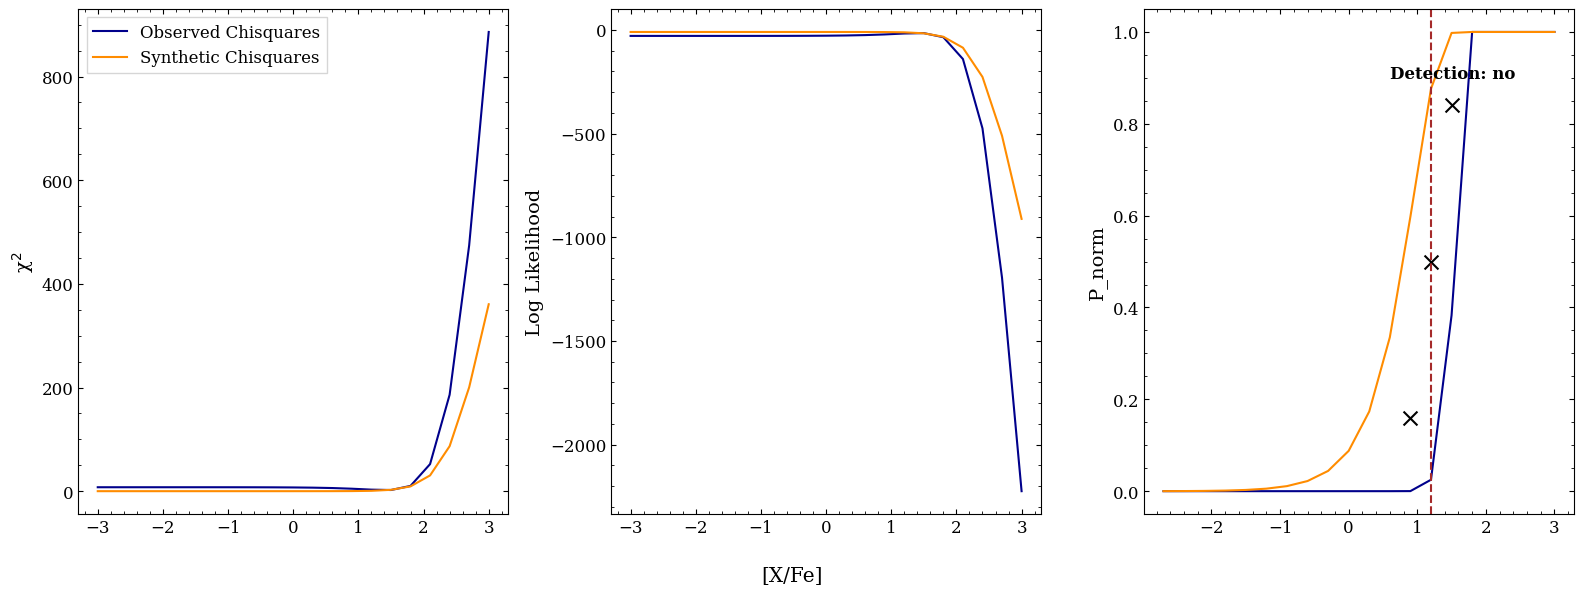

In [15]:
def lnL_obs(npix, flux_err, chisqrs):
    """Computes the log likelihood of a given observed dataset.

    Parameters
    ----------
    npix : int
        Number of pixels within the given wavelength region.
    flux_err : ndarray
        Array of observed flux errors.
    chisqrs : ndarray
        Array of chi-squared values.

    Returns
    -------
    ndarray
        Array of the observed log likelihoods for the dataset.
    """
    
    return -1/2 * (chisqrs * npix) + 1/2 * np.sum(np.log(np.sqrt(2 * np.pi) * flux_err))

def lnL_model(npix, flux_err, chisqrs):
    """Computes the log likelihood of a given model dataset.

    Parameters
    ----------
    npix : int
        Number of pixels within the given wavelength region.
    flux_err : ndarray
        Array of observed flux errors.
    chisqrs : ndarray
        Array of model chi-squared values.

    Returns
    -------
    ndarray
        Array of the observed log likelihoods for the dataset.
    """
    return -1/2 * (chisqrs * npix) + 1/2 * np.sum(np.log(np.sqrt(2 * np.pi) * flux_err))

def closest_val(array, x):
    """Within an array, finds the value closest to x.

    Parameters
    ----------
    array : ndarray
        Array of values.
    x : float
        Desired value to find closest entry to in array.

    Returns
    -------
    min_index : int
        Index of closest value to x in array.
    """
    arr_diff = np.abs(array - x) # Take x, then subtract that from every entry in the array
    min_index = np.argmin(arr_diff) # Finding the index of the smallest difference
    return min_index


def p_calc(lnL, abund_arr):
    """Performs the cumlative integral on a given log likelihood and [C/Fe] values.

    Parameters
    ----------
    lnL : ndarray
        Array of log likelihoods of dataset
    abund_arr : ndarray
        Array of [C/Fe] values.
        
    Returns
    -------
    p_norm : ndarray
        Array of normalized P values
    """
    
    # Performing the cumulative integral
    p = scipy.integrate.cumulative_trapezoid(y=np.exp(lnL - np.max(lnL)), x=10**abund_arr) # '- np.max(thing1)' to make numbers sensible.
    
    # Normalizing
    p_norm = p/np.max(p)
    
    return p_norm


# ---EXTRACTING THE CHISQUARE DATA--- #
# Flux data
flux_err = chisqr_df['obs_flux_err'].iloc[0]  # Extracting the flux error from the first row
npixels = len(flux_err)

# Chisquares and abundances
line_xfe_abunds = chisqr_df['abund'].to_numpy() 
line_obs_chisqrs = chisqr_df['obs_chi2'].to_numpy()  # Observed chi-squared values
line_synth_chisqrs = chisqr_df['empty_chi2'].to_numpy()  # Synthetic chi-squared values (empty spectrum)


# ---COMPUTING THE LOG LIKELIHOOD--- #
# Calculating the log likelihood for the observed data
star_lnL = lnL_obs(npix=npixels, flux_err=np.array(flux_err), chisqrs=line_obs_chisqrs)

# Calculating the cumulative integral for the observed log likelihood
star_pnorm = p_calc(lnL=star_lnL, abund_arr=line_xfe_abunds)
print(len(star_pnorm), len(line_xfe_abunds))

# Determining P_norm between P(x=1) and P(x=-1)
pnorm_m1 = scipy.stats.norm.cdf(x=-1)
pnorm_0 = scipy.stats.norm.cdf(x=0)
pnorm_p1 = scipy.stats.norm.cdf(x=1)

# Using these P_norm values to find corresponding [C/Fe] values
index_pnorm_m1 = closest_val(array=star_pnorm, x=pnorm_m1)
star_abund_m1 = line_xfe_abunds[index_pnorm_m1]

index_pnorm_0 = closest_val(array=star_pnorm, x=pnorm_0)
star_abund_p0 = line_xfe_abunds[index_pnorm_0]

index_pnorm_p1 = closest_val(array=star_pnorm, x=pnorm_p1)
star_abund_p1 = line_xfe_abunds[index_pnorm_p1]

# Finding correspondiong [C/Fe] 2sigma and 1 sigma errors
star_abund_2sig_err = star_abund_p1 - star_abund_m1
star_abund_1sig_err = star_abund_2sig_err/2


# ---COMPUTING THE NULL HYPOTHESIS--- #
# Calculating the log likelihood for the synthetic data
synth_lnL = lnL_model(npix=npixels, flux_err=np.array(flux_err), chisqrs=line_synth_chisqrs)

# Calculating the cumulative integral
synth_pnorm_xfemin = p_calc(lnL=synth_lnL, abund_arr=line_xfe_abunds)

# Determining detection limit at P(x=2)
pnorm_p2 = scipy.stats.norm.cdf(x=2)

index_synth_pnorm_p2 = closest_val(array=synth_pnorm_xfemin, x=pnorm_p2)
star_abund_p2 = line_xfe_abunds[index_synth_pnorm_p2] # 2sigma detection limit


# ---DETERMINING IF LINE IS DETECTED--- #
# If 2 sigma detection limit is greater than observed, then no detection. Otherwise detected.
if star_abund_p2 >= star_abund_p0:
    detect_flag = 'no'
    
if star_abund_p2 < star_abund_p0:
    detect_flag = 'yes'
    
print(f"Detection flag: {detect_flag}")
print(star_abund_p2, star_abund_p0)

# ---PLOTTING AND SAVING THE RESULTS--- #
# Plotting the following:
# 1. [X/Fe] vs Chisquares
# 2. [X/Fe] vs Log likelihood 
# 3. [X/Fe] vs P_norm
fig, axs = plt.subplots(1, 3, figsize=(16, 6), tight_layout=True)
axs[0].plot(line_xfe_abunds, line_obs_chisqrs, label='Observed Chisquares', color='darkblue')
axs[0].plot(line_xfe_abunds, line_synth_chisqrs, label='Synthetic Chisquares', color='darkorange')
axs[0].legend(fancybox=False)
axs[0].set_ylabel(r'χ$^2$')

axs[1].plot(line_xfe_abunds, star_lnL, label='Observed Log Likelihood', color='darkblue')
axs[1].plot(line_xfe_abunds, synth_lnL, label='Synthetic Log Likelihood', color='darkorange')
axs[1].set_ylabel(r'Log Likelihood')

axs[2].plot(line_xfe_abunds[1:], star_pnorm, label='Observed P_norm', color='darkblue')
axs[2].plot(line_xfe_abunds[1:], synth_pnorm_xfemin, label='Synthetic P_norm', color='darkorange')
axs[2].scatter(star_abund_m1, pnorm_m1, label='P(x=-1)', marker='x', color='black', s=100)
axs[2].scatter(star_abund_p0, pnorm_0, label='P(x=0)', marker='x', color='black', s=100)
axs[2].scatter(star_abund_p1, pnorm_p1, label='P(x=1)', marker='x', color='black', s=100)
axs[2].scatter(star_abund_p2, pnorm_p2, label='P(x=2)', marker='x', color='black', s=00)
axs[2].axvline(x=star_abund_p2, color='brown', linestyle='--', label='2 Sigma Detection Limit')
axs[2].set_ylabel(r'P_norm')
axs[2].text(s = f"Detection: {detect_flag}", x=0.6, y=0.9, fontweight='bold')

fig.supxlabel(r'[X/Fe]')

# plot_savepath = f"{el_save_path}{line}_log_likelihood.png"
# plt.savefig(plot_savepath, dpi=300, transparent=False, facecolor='white')
# plt.close()

In [17]:
star_pnorm

array([5.94978198e-11, 1.78211577e-10, 4.15076664e-10, 8.87684646e-10,
       1.83183994e-09, 3.73871329e-09, 7.68546377e-09, 1.62724210e-08,
       3.73832727e-08, 1.02220734e-07, 4.04566379e-07, 3.70406915e-06,
       1.50639585e-04, 2.48928532e-02, 3.82953589e-01, 9.99999997e-01,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00])